### 복습
- ChromaDB가 하는 역할: 문서를 임베딩 벡터로 만들고 저장
- 리트리버가 하는 역할: 원하는 알고리즘에 의해 질문과 의미가 가장 가까운 문서를 찾아주는 인터페이스
- SQL이 하는 역할: 관계형데이터베이스에서 원하는 데이터를 효율적으로 조회하고 조작할 수 있는 언어

___
# **1. SQLite**
- SQLite는 경량화된 관계형 데이터베이스
- 별도의 데이터베이스 서버를 설치하지 않고 파일로 사용하는 데이터베이스

모듈 설치: pip install sqlite3

In [11]:
import sqlite3
from pathlib import Path

In [12]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

simple_path = DATA_DIR / "hello.db"

In [13]:
conn_simple = sqlite3.connect(simple_path)
print("연결 성공:", simple_path.resolve())

연결 성공: D:\OSA\14_에이전트\data\hello.db


In [14]:
# 테이블 생성
conn_simple.execute("""
    CREATE TABLE IF NOT EXISTS students (
        id INTEGER PRIMARY KEY,
        name VARCHAR(20) NOT NULL,
        score INTEGER NOT NULL
    )
""")

SQLite Viewer 설치하고 data폴더에 hello.db 파일 보면 깔끔하게 보임

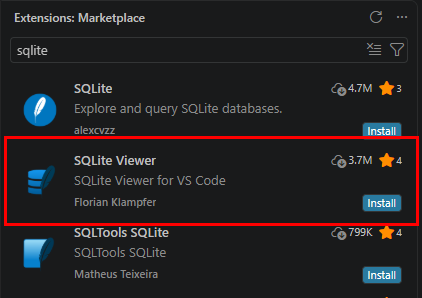


In [15]:
students = [(1, "김사과", 90), (2, "반하나", 85), (3, "오렌지", 95)]

# 이렇게 하면 데이터가 들어가는데~
# commit을 해줘야 실제로 데이터베이스에 반영됨
# why?
# SQLite는 기본적으로 트랜잭션을 사용함
# 데이터 변경(insert, update, delete)은 트랜잭션 안에서 이루어지고
# commit을 해야 실제로 데이터베이스에 반영됨
conn_simple.executemany("insert into students (id, name, score) values (?, ?, ?)", students)

conn_simple.commit()

print("학생 데이터 저장 완료")

OperationalError: database is locked

In [16]:
rows = conn_simple.execute("select name, score from students where score >= ? order by score desc", (90,)).fetchall()

for name, score in rows:
    print(name, score)

오렌지 95
김사과 90


In [17]:
import pandas as pd

In [18]:
pd.read_sql_query("SELECT * FROM students order by score desc", conn_simple)

,id,name,score
0,3,오렌지,95
1,1,김사과,90
2,2,반하나,85


In [19]:
# 작업 다 끝나면 DB 연결 끊어줘야함
conn_simple.close()
print("연습용 DB 연결 종료")

연습용 DB 연결 종료


### **1-1. 외부에 있는 데이터파일 받아와서 데이터프레임으로 읽어오기**
```
여기 접속하면 바로 받아짐
https://storage.googleapis.com/benchmarks-artifacts/chinook/Chinook.db
```



In [20]:
import requests

In [21]:
# 이 코드셀 실행하면 data 폴더에 Chinook.db 파일 다운로드됨
path = DATA_DIR / "Chinook.db"

# DB 파일 다운
if not path.exists():
    url = "https://storage.googleapis.com/benchmarks-artifacts/chinook/Chinook.db"
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    path.write_bytes(response.content)

print("DB 파일:", path.resolve())

conn = sqlite3.connect(path)
print("DB 연결 성공")

DB 파일: D:\OSA\14_에이전트\data\Chinook.db
DB 연결 성공


In [22]:
# 테이블 목록 가져오기
tables = conn.execute("SELECT name FROM sqlite_master WHERE type='table' order by name").fetchall()

print([name for (name,) in tables])

['Album', 'Artist', 'Customer', 'Employee', 'Genre', 'Invoice', 'InvoiceLine', 'MediaType', 'Playlist', 'PlaylistTrack', 'Track']


In [23]:
pd.read_sql_query("SELECT * FROM Customer limit 5", conn)

,CustomerId,FirstName,LastName,Company,Address,City,State,Country,PostalCode,Phone,Fax,Email,SupportRepId
0,1,Luís,Gonçalves,Embraer - Empresa Brasileira de Aeronáutica S.A.,"Av. Brigadeiro Faria Lima, 2170",São José dos Campos,SP,Brazil,12227-000,+55 (12) 3923-5555,+55 (12) 3923-5566,luisg@embraer.com.br,3
1,2,Leonie,Köhler,NaN,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,+49 0711 2842222,NaN,leonekohler@surfeu.de,5
2,3,François,Tremblay,NaN,1498 rue Bélanger,Montréal,QC,Canada,H2G 1A7,+1 (514) 721-4711,NaN,ftremblay@gmail.com,3
3,4,Bjørn,Hansen,NaN,Ullevålsveien 14,Oslo,NaN,Norway,0171,+47 22 44 22 22,NaN,bjorn.hansen@yahoo.no,4
4,5,František,Wichterlová,JetBrains s.r.o.,Klanova 9/506,Prague,NaN,Czech Republic,14700,+420 2 4172 5555,+420 2 4172 5555,frantisekw@jetbrains.com,4


In [24]:
# 주문별 고객 이름과 주문 금액(고객 이름은 customers 테이블, 주문 금액은 invoices 테이블에 있음)
pd.read_sql_query("""
    SELECT c.FirstName, c.LastName, i.Total
    FROM Customer c
    JOIN Invoice i 
        ON c.CustomerId = i.CustomerId
""", conn)

,FirstName,LastName,Total
0,Leonie,Köhler,1.98
1,Bjørn,Hansen,3.96
2,Daan,Peeters,5.94
3,Mark,Philips,8.91
4,John,Gordon,13.86
...,...,...,...
407,Victor,Stevens,3.96
408,Robert,Brown,5.94
409,Madalena,Sampaio,8.91
410,Terhi,Hämäläinen,13.86


In [25]:
# 집계합수: 국가별 주문 총액 상위 5개(국가별 총액은 invoices 테이블에 있음. 국가는 BillingCountry 컬럼에 있음)
pd.read_sql_query("""
    SELECT BillingCountry, SUM(Total)
    FROM Invoice
    GROUP BY BillingCountry
    ORDER BY SUM(Total) DESC
    LIMIT 5
""", conn)

,BillingCountry,SUM(Total)
0,USA,523.06
1,Canada,303.96
2,France,195.10
3,Brazil,190.10
4,Germany,156.48


___
# **2. LangChain으로 연결**

In [26]:
from langchain_community.utilities import SQLDatabase

C:\Users\sdesi\AppData\Local\Temp\ipykernel_21524\1266060898.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import SQLDatabase


In [27]:
# as_posix: 경로를 POSIX 형식으로 변환하여 SQLAlchemy에서 사용 (POSIX 형식 = / 형태)
db = SQLDatabase.from_uri(f"sqlite:///{path.resolve().as_posix()}")

print("DB 종류:", db.dialect)
print("테이블:", db.get_usable_table_names())
print("\nInvoice 테이블 구조 일부:")
print(db.get_table_info(['Invoice'])[:1200])

DB 종류: sqlite
테이블: ['Album', 'Artist', 'Customer', 'Employee', 'Genre', 'Invoice', 'InvoiceLine', 'MediaType', 'Playlist', 'PlaylistTrack', 'Track']

Invoice 테이블 구조 일부:

CREATE TABLE "Invoice" (
	"InvoiceId" INTEGER NOT NULL, 
	"CustomerId" INTEGER NOT NULL, 
	"InvoiceDate" DATETIME NOT NULL, 
	"BillingAddress" NVARCHAR(70), 
	"BillingCity" NVARCHAR(40), 
	"BillingState" NVARCHAR(40), 
	"BillingCountry" NVARCHAR(40), 
	"BillingPostalCode" NVARCHAR(10), 
	"Total" NUMERIC(10, 2) NOT NULL, 
	PRIMARY KEY ("InvoiceId"), 
	FOREIGN KEY("CustomerId") REFERENCES "Customer" ("CustomerId")
)

/*
3 rows from Invoice table:
InvoiceId	CustomerId	InvoiceDate	BillingAddress	BillingCity	BillingState	BillingCountry	BillingPostalCode	Total
1	2	2009-01-01 00:00:00	Theodor-Heuss-Straße 34	Stuttgart	None	Germany	70174	1.98
2	4	2009-01-02 00:00:00	Ullevålsveien 14	Oslo	None	Norway	0171	3.96
3	8	2009-01-03 00:00:00	Grétrystraat 63	Brussels	None	Belgium	1000	5.94
*/


In [28]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

In [29]:
# 있는지 확인용
load_dotenv(".env")

True

In [30]:
# OPENAI Key 가져오기
MODEL = os.getenv("OPENAI_MODEL", "gpt-5.6-luna")
llm = ChatOpenAI(model_name=MODEL, temperature=0)

In [31]:
from langchain_core.messages import HumanMessage

In [32]:
# 위에 SQL 할떄랑 다르게 대소문자 가리기때문에 확실히 써줘야함
schema = db.get_table_info(['Invoice', 'Customer', 'Employee'])
question = "2009년에 고객 담당 직원별 매출 합계 상위 3명을 알려줘"

# 원래는 저런 질문이 오면 SQL 테이블 구조를 보면서 쿼리 짜야하는데
# 이제 그럴 필요 없이 llm에게 맡기는거임
prompt = f"""
    SQLite SELECT 쿼리 하나만 작성하세요. 코드불록 없이 SQL만 출력하세요.
    스키마: {schema}
    질문: {question}
    조건: Invoice.Total의 합계를 사용하고 InvoiceDate는 2009년으로 제한합니다.
    고객의 SuppertRepId를 담당 직원으로 정의합니다. 결과는 최대 3행.
    INSERT/UPDATE/DELETE/DROP 등 데이터 변경문은 절대 금지합니다.
"""

In [33]:
# LLM에게 SQL 쿼리를 생성하도록 요청
raw_sql = llm.invoke([HumanMessage(content=prompt)]).content

# 우리가 원래 짜야 할 쿼리가 출력될거임
print(raw_sql)

SELECT
    e."EmployeeId",
    e."FirstName",
    e."LastName",
    SUM(i."Total") AS "TotalSales"
FROM "Invoice" AS i
JOIN "Customer" AS c
    ON i."CustomerId" = c."CustomerId"
JOIN "Employee" AS e
    ON c."SupportRepId" = e."EmployeeId"
WHERE i."InvoiceDate" >= '2009-01-01'
  AND i."InvoiceDate" < '2010-01-01'
GROUP BY e."EmployeeId", e."FirstName", e."LastName"
ORDER BY "TotalSales" DESC
LIMIT 3;


### **2-1. 기본적인 방어 코드**

In [34]:
import re

In [44]:
# 해킹 방지용 읽기 전용 쿼리 실행 함수
# 배포할 때 이 함수 통해서 SQL 실행되도록 하면 안전함
# 허용되지 않는 SQL함수 있으면 에러 발생시키는거임
def read_only_query(sql: str, max_rows=20):
    sql = re.sub(r"^```(?:sql)?\s*|\s*```$", "", sql.strip(), flags=re.I).strip()

    if not re.match(r"^(SELECT|WITH)\b", sql, flags=re.I):
        raise ValueError("SELECT 또는 WITH 형태의 단일 쿼리만 허용합니다.")
    if re.search(r"\b(INSERT|UPDATE|DELETE|DROP|ALTER|CREATE|ATTACH|DETACH|PRAGMA|REPLACE|VACUUM)\b", sql, flags=re.I):
        raise ValueError("허용되지 않는 SQL 키워드가 있습니다.")
    cur = conn.execute(sql)
    columns = [d[0] for d in cur.description]
    return pd.DataFrame(cur.fetchmany(max_rows), columns=columns)
try:
    display(read_only_query(raw_sql))
except Exception as exc:
    print(type(exc).__name__, str(exc))

,EmployeeId,FirstName,LastName,TotalSales
0,5,Steve,Johnson,164.34
1,4,Margaret,Park,161.37
2,3,Jane,Peacock,123.75


___
261110 수업내용

질문만들고 SQL만들고 실행 (에이전트는 안만들고)하는거 해보겠음

# **3. LangChain Tollkit**

- SQL Toolkit은 테이블 목록, 스키마 조회, 쿼리 검사, 실행 도구 등이 있는 키트임
- LangChain Toolkit 안에 SQL Toolkit이 포함되어 있음

In [45]:
from langchain_community.agent_toolkits import SQLDatabaseToolkit

In [46]:
toolkit = SQLDatabaseToolkit(db=db, llm=llm)

# 어떤 tool들이 있는지 확인
for tool in toolkit.get_tools():
    print(tool.name, ":", tool.description[:100])

sql_db_query : Input to this tool is a detailed and correct SQL query, output is a result from the database. If the
sql_db_schema : Input to this tool is a comma-separated list of tables, output is the schema and sample rows for tho
sql_db_list_tables : Input is an empty string, output is a comma-separated list of tables in the database.
sql_db_query_checker : Use this tool to double check if your query is correct before executing it. Always use this tool bef


In [47]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [48]:
class SQLState(TypedDict, total=False):
    question: str
    sql: str
    result: str
    answer: str
    error: str

def generate_sql(state: SQLState):
    p = f"""
        다음 SQLite 스키마만 사용해 SELECT SQL 하나를 만드세요.
        코드블록 없이 SQL만 출력하고 LIMIT 10을 포함하세요.
        스키마: {schema}
        질문: {state['question']}
    """
    return {"sql": llm.invoke(p).content}

def execute_sql(state: SQLState):
    try:
        df = read_only_query(state['sql'], max_rows=10)
        return {"result": df.to_json(orient="records", force_ascii=False), "error": ""}
    except Exception as e:
        return {"result": "", "error": str(e)}

# 코드작성할 때 발생할 수 있는 에러를 먼저 작성하고 처리하는게 센~스임~!
# 에러 먼저 잡아내고 진행시켜~!
def make_answer(state: SQLState):
    if state.get("error"):
        return {"answer": "쿼리 실행 실패" + state["error"]}
    msg = f"질문: {state['question']}\nSQL 조회 결과: {state['result']}\n조회 결과에 근거하여 한국어로 답하세요."
    return {"answer": llm.invoke(msg).content}

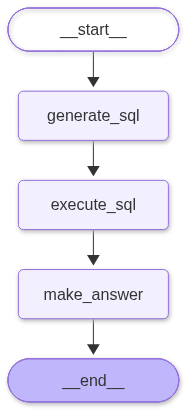

In [49]:
# 이제 그래프 만들어보자
builder = StateGraph(SQLState)

builder.add_node("generate_sql", generate_sql)
builder.add_node("execute_sql", execute_sql)
builder.add_node("make_answer", make_answer)

builder.add_edge(START, "generate_sql")
builder.add_edge("generate_sql", "execute_sql")
builder.add_edge("execute_sql", "make_answer")
builder.add_edge("make_answer", END)

sql_graph = builder.compile()

sql_graph

In [50]:
# 질문 내용: 한번에 나오는 쿼리 아니고 여기저기 뒤져서 나올 답임!
result = sql_graph.invoke({"question": "2009년 고객 담당 직원별 매출 합계 1위는 누구인가요?"})

print("생성 SQL:", result["sql"])
print("조회 결과:", result["result"])
print("최종 답변:", result["answer"])

생성 SQL: SELECT e."EmployeeId", e."FirstName", e."LastName", SUM(i."Total") AS "TotalSales"
FROM "Invoice" i
JOIN "Customer" c ON i."CustomerId" = c."CustomerId"
JOIN "Employee" e ON c."SupportRepId" = e."EmployeeId"
WHERE strftime('%Y', i."InvoiceDate") = '2009'
GROUP BY e."EmployeeId", e."FirstName", e."LastName"
ORDER BY "TotalSales" DESC
LIMIT 10;
조회 결과: [{"EmployeeId":5,"FirstName":"Steve","LastName":"Johnson","TotalSales":164.34},{"EmployeeId":4,"FirstName":"Margaret","LastName":"Park","TotalSales":161.37},{"EmployeeId":3,"FirstName":"Jane","LastName":"Peacock","TotalSales":123.75}]
최종 답변: 2009년 고객 담당 직원별 매출 합계 1위는 **Steve Johnson(직원 ID 5)**이며, 총매출은 **164.34**입니다.
